# Petals to the Metal -- Flower Classification on TPU

## **โจทย์:**
- จำแนกรูปดอกไม้ `104` ชนิด 
- วัดผลด้วย `Macro F1-score`
- คอลัมน์ `id`, `label`

## **Step 1**: imports, config, find TFRecord files

### Imports

In [1]:
import os, re
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


### Using CPU temporarily

In [2]:
strategy = tf.distribute.get_strategy()
REPLICAS = strategy.num_replicas_in_sync # คำนวณ batch size
AUTO = tf.data.AUTOTUNE # ให้ tf เลือกจำนวน thread ที่ใช้อ่านข้อมูลเอง

print("REPLICAS:", REPLICAS)

REPLICAS: 1


### Config

In [3]:
IMAGE_SIZE = [224, 224]   # ใช้ 224 ตอนทดลองบน CPU
EPOCHS = 12
BATCH_SIZE = 16 * REPLICAS
NUM_CLASSES = 104

KAGGLE_PATH = "/kaggle/input/tpu-getting-started"
LOCAL_PATH = "data/tpu-getting-started"
DATA_PATH = KAGGLE_PATH if os.path.exists(KAGGLE_PATH) else LOCAL_PATH
assert os.path.exists(DATA_PATH), "ไม่เจอข้อมูล — กด Add Input แล้วเลือก Petals to the Metal"

PATH = f"{DATA_PATH}/tfrecords-jpeg-{IMAGE_SIZE[0]}x{IMAGE_SIZE[1]}"
print(PATH)

data/tpu-getting-started/tfrecords-jpeg-224x224


In [4]:
TRAINING_FILENAMES   = tf.io.gfile.glob(PATH + "/train/*.tfrec")
VALIDATION_FILENAMES = tf.io.gfile.glob(PATH + "/val/*.tfrec")
TEST_FILENAMES       = tf.io.gfile.glob(PATH + "/test/*.tfrec")

assert TRAINING_FILENAMES, "ไม่เจอไฟล์ train — เช็ก PATH"
print("ตัวอย่างชื่อไฟล์:", os.path.basename(TRAINING_FILENAMES[0]))

def count_data_items(filenames):
    # ชื่อไฟล์เป็นแบบ 00-224x224-798.tfrec → ตัวเลขก่อน ".tfrec" คือจำนวนรูปในไฟล์
    return sum(int(re.search(r"-([0-9]+)\.", f).group(1)) for f in filenames)

NUM_TRAINING_IMAGES   = count_data_items(TRAINING_FILENAMES)
NUM_VALIDATION_IMAGES = count_data_items(VALIDATION_FILENAMES)
NUM_TEST_IMAGES       = count_data_items(TEST_FILENAMES)
STEPS_PER_EPOCH = NUM_TRAINING_IMAGES // BATCH_SIZE

print(f"train: {len(TRAINING_FILENAMES)} ไฟล์, {NUM_TRAINING_IMAGES} รูป")
print(f"val  : {len(VALIDATION_FILENAMES)} ไฟล์, {NUM_VALIDATION_IMAGES} รูป")
print(f"test : {len(TEST_FILENAMES)} ไฟล์, {NUM_TEST_IMAGES} รูป")
print("steps per epoch:", STEPS_PER_EPOCH)

ตัวอย่างชื่อไฟล์: 09-224x224-798.tfrec
train: 16 ไฟล์, 12753 รูป
val  : 16 ไฟล์, 3712 รูป
test : 16 ไฟล์, 7382 รูป
steps per epoch: 797


## Step 2: Decode TFRecord Data

### TFRecord
- คือรูปแบบไฟล์ของ `TensorFlow` ที่เก็บข้อมูลเป็น `Binary` โดยเก็บข้อมูลเรียงเป็นลำดับของ Record
- แต่ละ Record มักเป็น `tf.train.Example` ซึ่ง Serialize ด้วย Protocol Buffers
- โครงสร้าง
    - ไฟล์ .tfrec
        - record 1 → tf.train.Example { features: {"image": bytes, "class": int64, "id": bytes} }
        - record 2 → ...
        - ...
    - แต่ละ `Example` คือ dict ของ feature โดยแต่ละค่าเป็นได้ 3 ชนิด:
        - `BytesList` เช่นภาพที่ encode เป็น JPEG หรือข้อความ
        - `Int64List` เช่น label
        - `FloatList`

- ทำไมถึงนำมาใช้กับ TPU
    - อ่านได้เร็ว
    - TPU อ่านจาก Local Disk ไม่ได้ ต้องอ่านจาก Google Cloud Storage และใช้งานผ่าน TFRecord ได้
    - แบ่งเป็น Shard ได้ และอ่านพร้อมกันได้
    - ใช้กับ tf.data ได้ โดยการต่อกับ Pipeline ``` Shuffle --> Map --> Batch --> Prefetch``` ได้ทันที


### Check TFRecord
- `image` เก็บเป็น `bytes` ของไฟล์ JPEG ยังไม่ใช่ตัวเลขพิกเซล เราจึงต้อง decode เอง
- `train มี` `class` ซึ่งเป็น `label`
- `test` ไม่มี class แต่มี `id` ไว้ใส่ใน submission เพราะฉะนั้นต้องเขียนฟังก์ชันอ่านแยกเป็น 2 แบบ

In [5]:
def peek_tfrecord(filename):
    """อ่าน record แรกของไฟล์ แล้วพิมพ์ชื่อ feature, ชนิด และตัวอย่างค่า"""
    raw = next(iter(tf.data.TFRecordDataset(filename)))
    example = tf.train.Example.FromString(raw.numpy())
    for name, feature in example.features.feature.items():
        kind = feature.WhichOneof("kind")          # bytes_list / int64_list / float_list
        value = getattr(feature, kind).value[0]
        if kind == "bytes_list" and len(value) > 50:
            value = f"<ข้อมูล {len(value):,} bytes>"
        print(f"  {name:6s} {kind:11s} {value}")

print("TRAIN:"); peek_tfrecord(TRAINING_FILENAMES[0])
print("TEST:");  peek_tfrecord(TEST_FILENAMES[0])

TRAIN:
  class  int64_list  22
  image  bytes_list  <ข้อมูล 29,652 bytes>
  id     bytes_list  b'b515db4b4'
TEST:
  image  bytes_list  <ข้อมูล 40,360 bytes>
  id     bytes_list  b'52a88af32'


I0000 00:00:1791736168.977563  510045 tf_record_dataset_op.cc:390] TFRecordDataset `buffer_size` is unspecified, default to 262144


### Decode functions

In [6]:
def decode_image(image_data):
    image = tf.image.decode_jpeg(image_data, channels=3)   # bytes → พิกเซล uint8 (0–255)
    image = tf.cast(image, tf.float32) / 255.0             # → float 0–1
    image = tf.reshape(image, [*IMAGE_SIZE, 3])            # บอก shape ที่แน่นอน
    return image

def read_labeled_tfrecord(example):
    fmt = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "class": tf.io.FixedLenFeature([], tf.int64),
    }
    example = tf.io.parse_single_example(example, fmt)
    image = decode_image(example["image"])
    label = tf.cast(example["class"], tf.int32)
    return image, label

def read_unlabeled_tfrecord(example):
    fmt = {
        "image": tf.io.FixedLenFeature([], tf.string),
        "id":    tf.io.FixedLenFeature([], tf.string),
    }
    example = tf.io.parse_single_example(example, fmt)
    return decode_image(example["image"]), example["id"]

### Test with Actual Image
- Current version uses CPU (224)
- Later will be changed to TPU (512)

In [7]:
ds = tf.data.TFRecordDataset(TRAINING_FILENAMES).map(read_labeled_tfrecord)
print("element_spec:", ds.element_spec)

image, label = next(iter(ds))
print("shape :", image.shape)
print("dtype :", image.dtype)
print("range :", float(tf.reduce_min(image)), "→", float(tf.reduce_max(image)))
print("label :", int(label))

ds_test = tf.data.TFRecordDataset(TEST_FILENAMES).map(read_unlabeled_tfrecord)
img, idnum = next(iter(ds_test))
print("test  :", img.shape, idnum.numpy())

element_spec: (TensorSpec(shape=(224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(), dtype=tf.int32, name=None))
shape : (224, 224, 3)
dtype : <dtype: 'float32'>
range : 0.0 → 1.0
label : 22
test  : (224, 224, 3) b'52a88af32'


## Step 3: tf.data Pipeline, Data Augmentation
 

### Load Data & Data Augmentation

In [8]:
def load_dataset(filenames, labeled=True, ordered=False):
    options = tf.data.Options()
    options.deterministic = ordered        # False = ไม่สนลำดับ → เร็วขึ้น

    ds = tf.data.TFRecordDataset(filenames, num_parallel_reads=AUTO)
    ds = ds.with_options(options)
    ds = ds.map(read_labeled_tfrecord if labeled else read_unlabeled_tfrecord,
                num_parallel_calls=AUTO)
    return ds


def data_augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_brightness(image, 0.1)
    image = tf.image.random_saturation(image, 0.8, 1.2)
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label

### Pipelines for train / val / test

In [9]:
def get_training_dataset():
    ds = load_dataset(TRAINING_FILENAMES, labeled=True)
    ds = ds.map(data_augment, num_parallel_calls=AUTO)
    ds = ds.repeat()
    ds = ds.shuffle(2048)
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(AUTO)
    return ds


def get_validation_dataset(ordered=False):
    ds = load_dataset(VALIDATION_FILENAMES, labeled=True, ordered=ordered)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.cache()
    ds = ds.prefetch(AUTO)
    return ds


def get_test_dataset(ordered=True):
    ds = load_dataset(TEST_FILENAMES, labeled=False, ordered=ordered)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTO)
    return ds

### Test pipeline

In [10]:
train_ds = get_training_dataset()
images, labels = next(iter(train_ds))
print("train element_spec:", train_ds.element_spec[0].shape)
print("train batch       :", images.shape, labels.shape)
print("ค่าพิกเซลหลัง augment:", float(tf.reduce_min(images)), "→", float(tf.reduce_max(images)))

val_ds = get_validation_dataset()
print("val element_spec  :", val_ds.element_spec[0].shape)

n_val_batches = sum(1 for _ in val_ds)
print(f"val batches: {n_val_batches} (ควรได้ {int(np.ceil(NUM_VALIDATION_IMAGES / BATCH_SIZE))})")

train element_spec: (16, 224, 224, 3)
train batch       : (16, 224, 224, 3) (16,)
ค่าพิกเซลหลัง augment: 0.0 → 1.0
val element_spec  : (None, 224, 224, 3)
val batches: 232 (ควรได้ 232)


## Step 4: Show Sample Images

In [11]:
CLASSES = [
    'pink primrose', 'hard-leaved pocket orchid', 'canterbury bells', 'sweet pea', 'wild geranium',          # 00-04
    'tiger lily', 'moon orchid', 'bird of paradise', 'monkshood', 'globe thistle',                           # 05-09
    'snapdragon', "colt's foot", 'king protea', 'spear thistle', 'yellow iris',                              # 10-14
    'globe-flower', 'purple coneflower', 'peruvian lily', 'balloon flower', 'giant white arum lily',         # 15-19
    'fire lily', 'pincushion flower', 'fritillary', 'red ginger', 'grape hyacinth',                          # 20-24
    'corn poppy', 'prince of wales feathers', 'stemless gentian', 'artichoke', 'sweet william',              # 25-29
    'carnation', 'garden phlox', 'love in the mist', 'cosmos', 'alpine sea holly',                           # 30-34
    'ruby-lipped cattleya', 'cape flower', 'great masterwort', 'siam tulip', 'lenten rose',                  # 35-39
    'barberton daisy', 'daffodil', 'sword lily', 'poinsettia', 'bolero deep blue',                           # 40-44
    'wallflower', 'marigold', 'buttercup', 'daisy', 'common dandelion',                                      # 45-49
    'petunia', 'wild pansy', 'primula', 'sunflower', 'lilac hibiscus',                                       # 50-54
    'bishop of llandaff', 'gaura', 'geranium', 'orange dahlia', 'pink-yellow dahlia',                        # 55-59
    'cautleya spicata', 'japanese anemone', 'black-eyed susan', 'silverbush', 'californian poppy',           # 60-64
    'osteospermum', 'spring crocus', 'iris', 'windflower', 'tree poppy',                                     # 65-69
    'gazania', 'azalea', 'water lily', 'rose', 'thorn apple',                                                # 70-74
    'morning glory', 'passion flower', 'lotus', 'toad lily', 'anthurium',                                    # 75-79
    'frangipani', 'clematis', 'hibiscus', 'columbine', 'desert-rose',                                        # 80-84
    'tree mallow', 'magnolia', 'cyclamen', 'watercress', 'canna lily',                                       # 85-89
    'hippeastrum', 'bee balm', 'pink quill', 'foxglove', 'bougainvillea',                                    # 90-94
    'camellia', 'mallow', 'mexican petunia', 'bromelia', 'blanket flower',                                   # 95-99
    'trumpet creeper', 'blackberry lily', 'common tulip', 'wild rose',                                       # 100-103
]
assert len(CLASSES) == NUM_CLASSES, f"ได้ {len(CLASSES)} ชื่อ แต่ควรมี {NUM_CLASSES}"

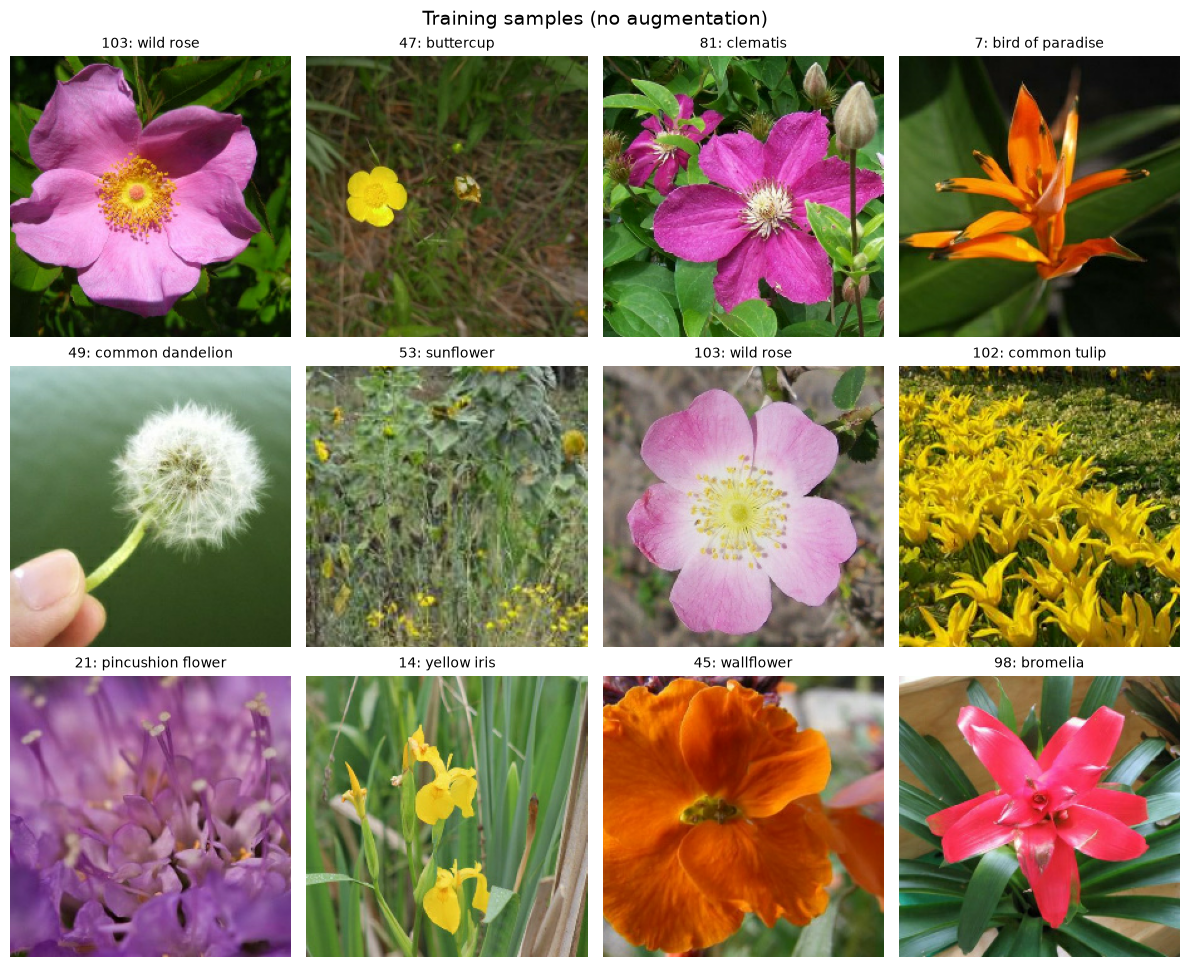

In [12]:
def show_images(images, titles, n_cols=4, suptitle=None):
    n_rows = int(np.ceil(len(images) / n_cols))
    plt.figure(figsize=(n_cols * 3, n_rows * 3.3))
    for i, (img, title) in enumerate(zip(images, titles)):
        plt.subplot(n_rows, n_cols, i + 1)
        plt.imshow(img)
        plt.title(title, fontsize=10)
        plt.axis("off")
    if suptitle:
        plt.suptitle(suptitle, fontsize=14)
    plt.tight_layout()
    plt.show()

samples = list(load_dataset(TRAINING_FILENAMES).shuffle(500).take(12))
images = [img.numpy() for img, _ in samples]
titles = [f"{int(lbl)}: {CLASSES[int(lbl)]}" for _, lbl in samples]
show_images(images, titles, suptitle="Training samples (no augmentation)")

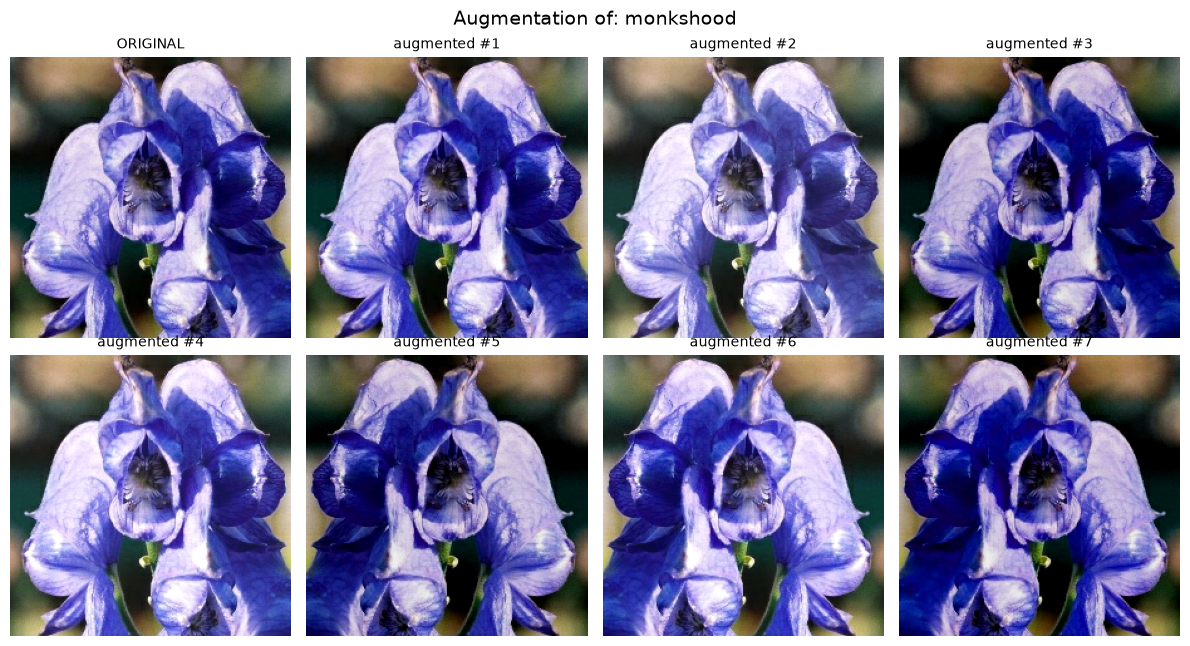

In [13]:
image, label = next(iter(load_dataset(TRAINING_FILENAMES)))

variants = [image.numpy()] + [data_augment(image, label)[0].numpy() for _ in range(7)]
titles   = ["ORIGINAL"] + [f"augmented #{i}" for i in range(1, 8)]
show_images(variants, titles, suptitle=f"Augmentation of: {CLASSES[int(label)]}")

รวม: 12753

มากสุด 3 ชนิด:
   67 iris                      782 รูป
  103 wild rose                 743 รูป
    4 wild geranium             703 รูป
น้อยสุด 3 ชนิด:
   34 alpine sea holly          18 รูป
   44 bolero deep blue          18 รูป
    6 moon orchid               18 รูป

ต่างกัน 43 เท่า


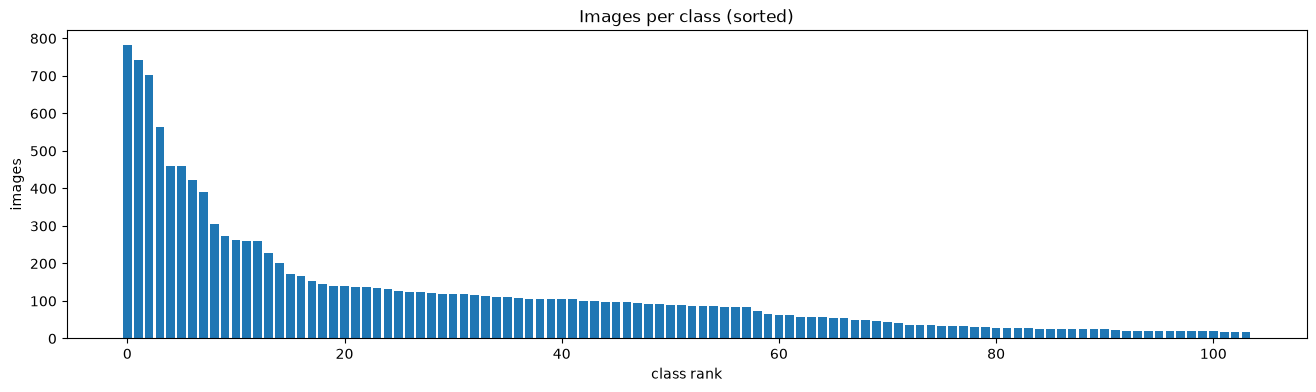

In [14]:
def read_label_only(example):
    fmt = {"class": tf.io.FixedLenFeature([], tf.int64)}
    return tf.io.parse_single_example(example, fmt)["class"]

def count_labels(filenames):
    ds = (tf.data.TFRecordDataset(filenames, num_parallel_reads=AUTO)
            .map(read_label_only, num_parallel_calls=AUTO)
            .batch(4096))
    labels = np.concatenate([b.numpy() for b in ds])
    return np.bincount(labels, minlength=NUM_CLASSES)

train_counts = count_labels(TRAINING_FILENAMES)
print("รวม:", train_counts.sum())

order = np.argsort(train_counts)[::-1]
print("\nมากสุด 3 ชนิด:")
for c in order[:3]:  print(f"  {c:3d} {CLASSES[c]:25s} {train_counts[c]} รูป")
print("น้อยสุด 3 ชนิด:")
for c in order[-3:]: print(f"  {c:3d} {CLASSES[c]:25s} {train_counts[c]} รูป")
print(f"\nต่างกัน {train_counts.max() / train_counts.min():.0f} เท่า")

plt.figure(figsize=(16, 4))
plt.bar(range(NUM_CLASSES), train_counts[order])
plt.title("Images per class (sorted)")
plt.xlabel("class rank"); plt.ylabel("images")
plt.show()